In [70]:
from typing import Annotated

from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
#statgrapph is actually used to maintain the context of the state your entire pipeline you can say from start to end is called as statgraph
from langgraph.graph.message import add_messages
# this add_messages is a reducer and it is repsonsible to adding the messages to the state means will append the chatbot and human messages to the list to make sure the chat bot remebrs the chat
# add_messages helps maintain the conversation/message history inside your LangGraph state.

In [71]:
class State(TypedDict):

    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

class State(TypedDict):
    messages: Annotated[list, add_messages]


    |

this menas this
{
    "messages":[
        HumanMessage(content="hi"),
        AIMessage(content="hello how are you")
    ]
}

so your chatbot then will be having whole state

In [72]:
graph_builder

In [73]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

In [74]:
from langchain_groq import ChatGroq

llm=ChatGroq(model='openai/gpt-oss-120b')

In [75]:
#node functinoality
def chatbot(state:State):
    return {
        "messages":[
            llm.invoke(state['messages'])
        ]
    }

now see in the above we are defining state:State 
State class we created to maintain chat state
so we passsed that here...
now wehn we call state['messages']

we are actuallay calling the messages from State class 

class State(TypedDict):

    messages:Annotated[list,add_messages]
graph_builder=StateGraph(State)

messages:Annotated[list,add_messages] ->this messages

In [76]:
# now create the whole graph
#defining the grpah

graph_builder=StateGraph(State)

# adding node
graph_builder.add_node("llm_chatbot",chatbot)

# adding edges
graph_builder.add_edge(START,"llm_chatbot")
graph_builder.add_edge("llm_chatbot",END)

the graph will look like this

    <start>
       |
    llm_chatbot
       |
    <END>

In [77]:
#after defining next is to compile the grpah

graph=graph_builder.compile()

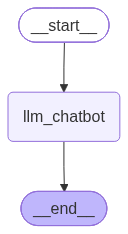

In [78]:
#visualize the graph

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [79]:
graph.invoke({"messages":"hello my self azra"})

{'messages': [HumanMessage(content='hello my self azra', additional_kwargs={}, response_metadata={}, id='75504090-ba73-4425-8023-f360086f8b0d'),
  AIMessage(content='Hello Azra! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "hello my self azra". Probably a greeting, wants a response. Should respond politely, ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 76, 'total_tokens': 133, 'completion_time': 0.122076943, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.003520344, 'prompt_tokens_details': None, 'queue_time': 0.052189316, 'total_time': 0.125597287}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5e2577217c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a116b5-c5c5-76d3-9070-cc54a9e5be29-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_to

In [80]:
graph.invoke({"messages":"do you know me?what is my name?"})

{'messages': [HumanMessage(content='do you know me?what is my name?', additional_kwargs={}, response_metadata={}, id='fe433c01-cf90-406a-8877-0e747df8b188'),
  AIMessage(content='I don’t have any information about you, so I don’t know your name. If you’d like to share it—or anything else you think would be helpful for our conversation—just let me know!', additional_kwargs={'reasoning_content': 'The user asks: "do you know me? what is my name?" The system says we must follow policy. We don\'t have any prior context. We cannot guess personal info. We must respond that we don\'t know their name unless they tell us. We can ask politely. Also we must not ask for personal data? It\'s allowed to ask for name if needed for conversation, but we should be cautious. We can respond: I don\'t know your name. If you\'d like to share, let me know.'}, response_metadata={'token_usage': {'completion_tokens': 152, 'prompt_tokens': 81, 'total_tokens': 233, 'completion_time': 0.319433899, 'completion_token

In [81]:
import os
from dotenv import load_dotenv

load_dotenv()
os.environ['TAVILY_API_KEY']=os.getenv('TAVILY_API_KEY')

In [82]:
#chatbot with tool
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("recent news?")

{'query': 'recent news?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.cnn.com',
   'title': 'Breaking News, Latest News and Videos | CNN',
   'content': "Michigan Democratic Senate candidate Abdul El-Sayed arrives to a press conference on September 22, in Detroit.\nJared Kushner speaks during the inaugural meeting of the Board of Peace in Washington, DC, on February 19, 2026.\nThe badges of Immigration and Customs Enforcement agents are seen as they patrol the halls of an immigration court in New York in May.\nStudents walk along Cornell University’s main promenade on a quiet morning on October 6, 2026. [...] Police stand guard as a student holds a board reading 'they want the BAC (High School Diploma) Not the BAC (Anti-criminality units)' during a protest against under-resourced schools, in Paris, on Wednesday.\nA protester throws a garbage bin into burning objects during a demonstration by high school and university students, in Par

In [83]:
# custom fucntion
def multiply(a:int,b:int)->int:
    """this function will do multiplication of two numbers
        Args:
            a(int) : first integer numner
            b(int) : second integer number

            and the multiplication operation needs to be perform between these two

        Returns:
            int : answer by multiplying two numbers a and b
    """
    return a*b


In [84]:
# custom fucntion
def weather(city:str):
    """this function will dispaly information about the weather """
    return f"there will be sunny in {city}"

In [85]:
tools=[tool,multiply,weather] # tavily tool and mulipy tool

In [86]:
llm_with_tools=llm.bind_tools(tools)

In [87]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000167E3AEA270>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000167E3B28710>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

                 ┌─── tool call? ───→ TOOLS
                 │
START → LLM ─────┤
                 │
                 └─── no tool call ─→ END

In [88]:
# stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

# node defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state['messages'])]}

builder=StateGraph(State)

builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools)) 


builder.add_edge(START,"tool_calling_llm")
# builder.add_edge("tool_calling_llm","tools") will not doo this because there are conditional endges now what it means
# means llm will call either a tool or it may not based upon the user input... okk...so thatswhy it is called conditional_edge
builder.add_conditional_edges(
    "tool_calling_llm",
    # see if output from llm is calling to a tool (a tool call ) then tools_condition routes to the tools
    # if the result or output from the llm is not a tool call then end it....soo that whyy the below add_edge from tools to end
    tools_condition
)
builder.add_edge("tools",END)

graph=builder.compile()

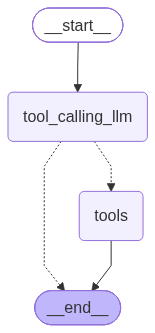

In [89]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [90]:
graph.invoke({"messages":"tommorows weather wil be??and should i carry umbrealla?I am in Ratnagiri, Maharashtra, India. I'm asking about October 8, 2026."})

{'messages': [HumanMessage(content="tommorows weather wil be??and should i carry umbrealla?I am in Ratnagiri, Maharashtra, India. I'm asking about October 8, 2026.", additional_kwargs={}, response_metadata={}, id='1994d87e-d664-4141-8518-eafb10fdeb85'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks for weather forecast for tomorrow (Oct 8, 2026) in Ratnagiri, Maharashtra, India, and whether to carry an umbrella. Need to retrieve weather forecast. Use weather tool. Provide answer with forecast details and recommendation.', 'tool_calls': [{'id': 'fc_596667ae-31fc-4714-a11e-0af5d2e8bb53', 'function': {'arguments': '{"city":"Ratnagiri, Maharashtra, India"}', 'name': 'weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 436, 'total_tokens': 520, 'completion_time': 0.181446121, 'completion_tokens_details': {'reasoning_tokens': 52}, 'prompt_time': 0.085957455, 'prompt_tokens_details': None, 'queue_time'

see this is thee issue llm can search for the weatherr and tell you "there will be sunny in Ratnagiri(from tool) " but it cant say you backk whetehr youcarry umbrealla or bnnot so for thats whyy we have to build another graph that will again call the llmm and will give you repsonse back

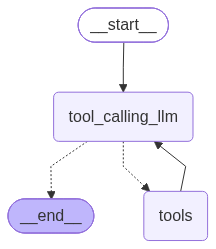

In [91]:
# building another graph that will call the llm again

builder2=StateGraph(State)

builder2.add_node("tool_calling_llm",tool_calling_llm)
builder2.add_node("tools",ToolNode(tools))

builder2.add_edge(START,"tool_calling_llm")
builder2.add_conditional_edges("tool_calling_llm",tools_condition)
builder2.add_edge("tools","tool_calling_llm")

graph2=builder2.compile()

display(Image(graph2.get_graph().draw_mermaid_png()))

In [92]:
result=graph2.invoke({"messages":"tommorows weather wil be??and should i carry umbrealla?I am in Ratnagiri, Maharashtra, India. I'm asking about October 8, 2026."})

In [93]:
result

{'messages': [HumanMessage(content="tommorows weather wil be??and should i carry umbrealla?I am in Ratnagiri, Maharashtra, India. I'm asking about October 8, 2026.", additional_kwargs={}, response_metadata={}, id='3620c6cf-0f04-4b99-bda6-a9ea2c8c3306'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks about tomorrow\'s weather and whether to carry an umbrella, location Ratnagiri, Maharashtra, India, date October 8, 2026. Need to fetch weather forecast. Use weather function? It takes city name, likely returns current weather, not forecast. Might need to search. Use tavily_search with query "Ratnagiri weather October 8 2026 forecast". Let\'s do search.', 'tool_calls': [{'id': 'fc_e8c54be6-4530-4148-89f7-3fac1b522778', 'function': {'arguments': '{"query":"Ratnagiri Maharashtra weather forecast October 8 2026","search_depth":"advanced","time_range":"year"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens'

In [94]:
from langchain_core.messages import AIMessage

for message in result["messages"]:
    if isinstance(message, AIMessage):
        print(message.content)




**Weather forecast for Ratnagiri (Maharashtra, India) – 8 October 2026**

| Time of day | Expected condition | Temperature | Chance of rain |
|-------------|-------------------|-------------|----------------|
| Morning‑midday | Clear sky (few clouds) | ~ 29 – 31 °C | 0 % |
| Evening‑night | Clear sky | ~ 28 – 30 °C | 0 % |

*Source:* The 14‑day forecast from **Ventusky** shows “clear sky” for Thursday 08 Oct 2026 with no precipitation recorded for any hour of the day and temperatures ranging from the high‑20s to low‑30s °C【8bb352-00】.

### Should you carry an umbrella?
- **No.** The forecast predicts no rain (0 mm precipitation, 0 % chance) and very low cloud cover. An umbrella would not be needed.

### What to pack
- Light, breathable clothing for warm temperatures (≈ 30 °C).  
- Sun protection (hat, sunscreen) – the sky will be clear.  
- A light jacket for the evening if you tend to feel cool after sunset.

**Bottom line:** Expect a sunny, warm day with virtually no chance of rai

In [97]:
response2=graph2.invoke({"messages":"waht is ai in one line and also give multiplication of 10 by 2"})

for r in response2['messages']:
    r.pretty_print()

================================ Human Message =================================

waht is ai in one line and also give multiplication of 10 by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_ed0b2e6d-0012-4c57-8c52-2fa618514b4f)
 Call ID: fc_ed0b2e6d-0012-4c57-8c52-2fa618514b4f
  Args:
    a: 10
    b: 2
================================= Tool Message =================================
Name: multiply

20
================================== Ai Message ==================================

AI is the simulation of human intelligence by machines.  
10 × 2 = 20.
